In [7]:
# Descargar y cargar el dataset


import pandas as pd
import numpy as np
import requests
import zipfile
import io
from pathlib import Path

# Crear estructura de carpetas
base = Path("Actividad5")
original = base / "datos" / "datos_ini"
limpio = base / "datos" / "datos_limp"

original.mkdir(parents=True, exist_ok=True)
limpio.mkdir(parents=True, exist_ok=True)

# Descargar dataset original de UCI
url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
respuesta = requests.get(url, timeout=120)
respuesta.raise_for_status()

with zipfile.ZipFile(io.BytesIO(respuesta.content)) as externo:
    with zipfile.ZipFile(io.BytesIO(externo.read("bank.zip"))) as interno:
        archivo = interno.read("bank-full.csv")

ruta_original = original / "bank-full.csv"
ruta_original.write_bytes(archivo)

df = pd.read_csv(ruta_original, sep=";")

print("Dimensiones originales:", df.shape)
display(df.head())


Dimensiones originales: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [8]:
# Diagnóstico de calidad

print("=== DIAGNÓSTICO INICIAL ===")
print("Filas:", len(df))
print("Columnas:", len(df.columns))
print("Valores nulos:", df.isna().sum().sum())
print("Filas duplicadas:", df.duplicated().sum())

print("\nTipos de datos:")
print(df.dtypes.value_counts())

print("\nValores 'unknown' por variable:")
for columna in df.select_dtypes(include="object"):
    cantidad = (df[columna] == "unknown").sum()
    if cantidad > 0:
        print(f"{columna}: {cantidad}")

print("\nDistribución de la variable objetivo:")
print(df["y"].value_counts())


=== DIAGNÓSTICO INICIAL ===
Filas: 45211
Columnas: 17
Valores nulos: 0
Filas duplicadas: 0

Tipos de datos:
object    10
int64      7
Name: count, dtype: int64

Valores 'unknown' por variable:
job: 288
education: 1857
contact: 13020
poutcome: 36959

Distribución de la variable objetivo:
y
no     39922
yes     5289
Name: count, dtype: int64


In [9]:
# Limpieza y aplicación de reglas

# Trabajar sobre una copia del dataset original
df_limpio = df.copy()

# Identificar duplicados exactos originales
duplicados_originales = df_limpio.duplicated().sum()

# Eliminar duplicados exactos originales
df_limpio = df_limpio.drop_duplicates().copy()

# Excluir variable que genera fuga de información
df_limpio = df_limpio.drop(columns=["duration"])

# Identificar coincidencias después de quitar duration
coincidencias = df_limpio.duplicated().sum()

# Validar variable objetivo
assert df_limpio["y"].isin(["yes", "no"]).all()

# Validar edades
assert df_limpio["age"].between(18, 100).all()

# Validar que no existan duplicados originales
assert not df.duplicated().sum() - duplicados_originales

# Guardar archivo limpio
ruta_limpia = limpio / "bank_limpio.csv"
df_limpio.to_csv(ruta_limpia, index=False)

# Mostrar resultados
print("=== RESULTADO DE LIMPIEZA ===")
print("Registros originales:", len(df))
print("Duplicados originales eliminados:", duplicados_originales)
print("Registros finales:", len(df_limpio))
print("Columnas finales:", len(df_limpio.columns))
print("Valores nulos:", df_limpio.isna().sum().sum())
print("Coincidencias tras excluir duration:", coincidencias)
print("Archivo guardado:", ruta_limpia)


=== RESULTADO DE LIMPIEZA ===
Registros originales: 45211
Duplicados originales eliminados: 0
Registros finales: 45211
Columnas finales: 16
Valores nulos: 0
Coincidencias tras excluir duration: 16
Archivo guardado: Actividad5/datos/datos_limp/bank_limpio.csv


In [10]:
# Preparar las transformaciones para los modelos

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Variable objetivo y características
X = df_limpio.drop(columns=["y"])
y = df_limpio["y"].map({"no": 0, "yes": 1})

numericas = X.select_dtypes(include=np.number).columns.tolist()
categoricas = X.select_dtypes(exclude=np.number).columns.tolist()

# Pipeline para regresión logística
prep_logistica = ColumnTransformer([
    ("numericas", StandardScaler(), numericas),
    ("categoricas", OneHotEncoder(handle_unknown="ignore"), categoricas)
])

# Pipeline para random forest
prep_forest = ColumnTransformer([
    ("numericas", "passthrough", numericas),
    ("categoricas", OneHotEncoder(handle_unknown="ignore"), categoricas)
])

print("Variables numéricas:", numericas)
print("Variables categóricas:", categoricas)
print("Variables predictoras:", X.shape[1])
print("Variable objetivo: y")
print("Transformaciones configuradas correctamente.")


Variables numéricas: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Variables categóricas: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Variables predictoras: 15
Variable objetivo: y
Transformaciones configuradas correctamente.


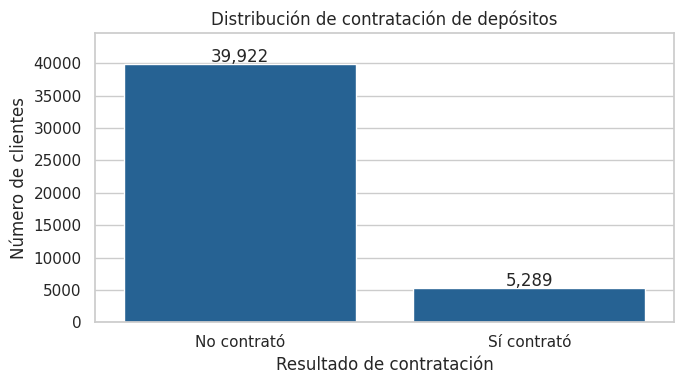

Porcentajes de contratación:
y
no     88.3
yes    11.7
Name: count, dtype: float64


In [11]:
# Distribución de la variable objetivo

import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Carpeta para guardar gráficas
graficas = Path("Actividad5/evidencias")
graficas.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

conteo = df_limpio["y"].value_counts().reindex(["no", "yes"])
porcentaje = conteo / conteo.sum() * 100

plt.figure(figsize=(7, 4))
ax = sns.barplot(
    x=["No contrató", "Sí contrató"],
    y=conteo.values,
    color="#1464A5"
)

for i, valor in enumerate(conteo.values):
    ax.text(i, valor + 300, f"{valor:,}", ha="center")

plt.title("Distribución de contratación de depósitos")
plt.ylabel("Número de clientes")
plt.xlabel("Resultado de contratación")
plt.ylim(0, conteo.max() * 1.12)
plt.tight_layout()
plt.savefig(graficas / "figura4_contratacion.png", dpi=160)
plt.show()

print("Porcentajes de contratación:")
print(porcentaje.round(2))


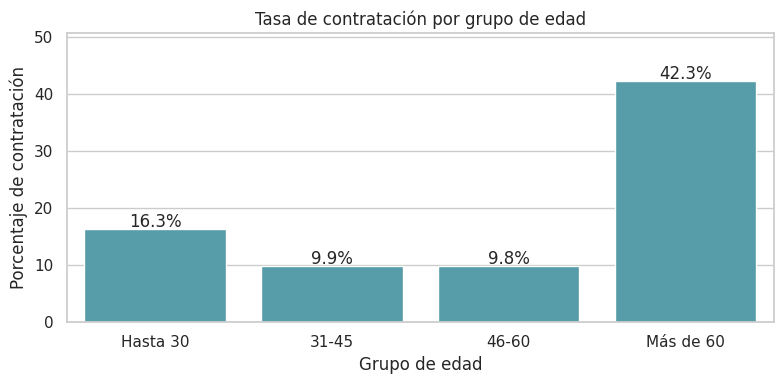

grupo_edad
Hasta 30     16.29
31-45         9.88
46-60         9.78
Más de 60    42.26
Name: y, dtype: float64


In [12]:
# Contratación por grupo de edad

# Crear grupos de edad
df_eda = df_limpio.copy()

df_eda["grupo_edad"] = pd.cut(
    df_eda["age"],
    bins=[0, 30, 45, 60, float("inf")],
    labels=["Hasta 30", "31-45", "46-60", "Más de 60"]
)

# Calcular tasa de contratación por grupo
tasas = (
    df_eda.groupby("grupo_edad", observed=True)["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
)

plt.figure(figsize=(8, 4))
ax = sns.barplot(
    x=tasas.index.astype(str),
    y=tasas.values,
    color="#49A5B7"
)

for i, valor in enumerate(tasas.values):
    ax.text(i, valor + 0.4, f"{valor:.1f}%", ha="center")

plt.title("Tasa de contratación por grupo de edad")
plt.xlabel("Grupo de edad")
plt.ylabel("Porcentaje de contratación")
plt.ylim(0, max(tasas.values) * 1.2)
plt.tight_layout()
plt.savefig(graficas / "figura5_edad.png", dpi=160)
plt.show()

print(tasas.round(2))


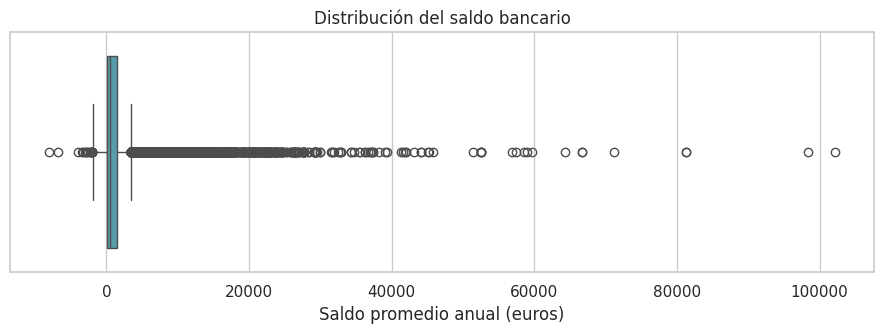

=== ANÁLISIS DEL SALDO ===
Saldo mínimo: -8019
Saldo máximo: 102127
Mediana: 448.0
Valores atípicos (IQR): 4729
Porcentaje atípico: 10.46


In [13]:
# Identificación de valores atípicos

plt.figure(figsize=(9, 3.5))

sns.boxplot(
    x=df_limpio["balance"],
    color="#49A5B7"
)

plt.title("Distribución del saldo bancario")
plt.xlabel("Saldo promedio anual (euros)")
plt.tight_layout()
plt.savefig(graficas / "figura6_saldo.png", dpi=160)
plt.show()

# Identificar valores atípicos con el método IQR
q1 = df_limpio["balance"].quantile(0.25)
q3 = df_limpio["balance"].quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

atipicos = (
    (df_limpio["balance"] < limite_inferior) |
    (df_limpio["balance"] > limite_superior)
).sum()

print("=== ANÁLISIS DEL SALDO ===")
print("Saldo mínimo:", df_limpio["balance"].min())
print("Saldo máximo:", df_limpio["balance"].max())
print("Mediana:", df_limpio["balance"].median())
print("Valores atípicos (IQR):", atipicos)
print("Porcentaje atípico:", round(atipicos / len(df_limpio) * 100, 2))


In [14]:
# Crear README.md

from pathlib import Path

base = Path("Actividad5")
base.mkdir(exist_ok=True)

readme = """# Actividad 5 - Machine Learning y MLOps

## Descripción
Predicción de contratación de depósitos bancarios mediante
regresión logística y random forest.

## Dataset
Nombre: Bank Marketing
Fuente: UCI Machine Learning Repository
URL: https://archive.ics.uci.edu/dataset/222/bank+marketing

## Preparación de datos
- 45,211 registros originales.
- 17 columnas originales.
- Sin valores nulos.
- Sin duplicados exactos originales.
- Exclusión de la variable duration.
- Conservación de valores unknown y pdays = -1.
- Dataset preparado: 45,211 registros y 16 columnas.

## Análisis exploratorio
- Contratación positiva: 11.7%.
- Contratación negativa: 88.3%.
- Valores atípicos de balance: 4,729 (10.46%).
- Mayor tasa de contratación por edad: mayores de 60 años.

## Modelos
1. Regresión logística.
2. Random forest.

## Metodología
- Preparación mediante pipelines de scikit-learn.
- Validación cruzada de 5 particiones.
- Optimización mediante GridSearchCV.
- Evaluación con accuracy, precision, recall, F1 y ROC-AUC.
- Registro de experimentos mediante MLflow.

## Estructura
- datos/datos_ini: datos originales.
- datos/datos_limp: datos preparados.
- fuentes: notebook y scripts Python.
- evidencias: gráficas y capturas.
- CHANGELOG.md: historial de cambios.

## Reproducción
Los pasos de instalación y ejecución se completarán
cuando finalice la implementación de los modelos.

## Consideraciones
Proyecto académico basado en datos públicos.
No utiliza información de clientes de BBVA.
"""

(base / "README.md").write_text(readme, encoding="utf-8")

print("README.md creado correctamente")


README.md creado correctamente


In [15]:
# Crear CHANGELOG.md

changelog = """# Historial de cambios - Actividad 5

## Versión 0.1.0 - Preparación inicial

### Incorporado
- Dataset original Bank Marketing.
- Estructura de carpetas del proyecto.
- Diagnóstico de calidad de datos.
- Archivo de datos preparados.
- Análisis exploratorio con tres visualizaciones.
- Configuración inicial de transformadores.

### Resultados
- Registros originales: 45,211.
- Duplicados exactos originales: 0.
- Valores nulos: 0.
- Registros finales: 45,211.
- Columnas finales: 16.
- Coincidencias tras excluir duration: 16.

### Decisiones técnicas
- Se excluyó duration para evitar fuga de información.
- Se conservaron los valores categóricos unknown.
- Se mantuvo pdays = -1 por su significado.
- No se eliminaron automáticamente valores atípicos.
- Se conservaron coincidencias posteriores a la exclusión
  de duration por no demostrar duplicación real.

## Pendiente
- Entrenamiento de modelos.
- Ajuste de hiperparámetros.
- Registro de experimentos en MLflow.
- Evaluación comparativa.
"""

(base / "CHANGELOG.md").write_text(
    changelog, encoding="utf-8"
)

print("CHANGELOG.md creado correctamente")


CHANGELOG.md creado correctamente


In [16]:
# Crear requirements.txt y .gitignore

requirements = """pandas
numpy
scikit-learn
matplotlib
seaborn
mlflow
requests
"""

gitignore = """__pycache__/
*.pyc
.ipynb_checkpoints/
mlruns/
mlartifacts/
mlflow.db
.env
"""

(base / "requirements.txt").write_text(
    requirements, encoding="utf-8"
)

(base / ".gitignore").write_text(
    gitignore, encoding="utf-8"
)

(base / "fuentes").mkdir(exist_ok=True)

print("Archivos complementarios creados")


Archivos complementarios creados


In [17]:
# Comprobar archivos

print("=== ESTRUCTURA ACTUAL DEL PROYECTO ===")

for archivo in sorted(base.rglob("*")):
    if archivo.is_file():
        print(archivo)


=== ESTRUCTURA ACTUAL DEL PROYECTO ===
Actividad5/.gitignore
Actividad5/CHANGELOG.md
Actividad5/README.md
Actividad5/datos/datos_ini/bank-full.csv
Actividad5/datos/datos_limp/bank_limpio.csv
Actividad5/evidencias/figura4_contratacion.png
Actividad5/evidencias/figura5_edad.png
Actividad5/evidencias/figura6_saldo.png
Actividad5/requirements.txt


In [18]:
# Descargar el proyecto

import shutil
from google.colab import files

archivo_zip = shutil.make_archive(
    "Actividad5_respaldo", "zip",
    root_dir=".", base_dir="Actividad5"
)

files.download(archivo_zip)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>